In [1]:
%load_ext autoreload
%autoreload 2

import sys
import importlib
from pathlib import Path
import cv2
import numpy as np
import torch
# Resolve paths
PROJECT_ROOT = Path("..").resolve()
SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.append(str(SRC_DIR))

# Import pipeline classes and utilities
from dataset import ImageDataset
from feature_matching import FeatureMatcher
from pose_estimation import PoseEstimator
from triangulation import Triangulator
from bundle_adjustment import BundleAdjuster
from utils import build_intrinsic_matrix, export_ply
from feature_tracks import TrackGraph
import itertools

In [2]:
# 1. Load Dataset
dataset = ImageDataset()
print(f"Loaded {len(dataset)} images.")

# 2. Build Intrinsic Matrix K
height, width = dataset[0].shape[:2]
K = build_intrinsic_matrix(width=width, height=height)

# 3. Instantiate Pipeline Modules
matcher = FeatureMatcher()
estimator = PoseEstimator(K)
triangulator = Triangulator(K)
optimizer = BundleAdjuster(K)
track_graph = TrackGraph()

Loaded 177 images.


In [3]:
# 1. Pre-extract features for the entire dataset
all_kp, all_des = {}, {}
print(f"Extracting features for all {len(dataset)} images...")
for i in range(len(dataset)):
    kp, des = matcher.extract_features(dataset[i])
    all_kp[i], all_des[i] = kp, des

# 2. Push to GPU VRAM
print("Pushing all descriptors to GPU VRAM...")
all_des_gpu = {
    i: torch.tensor(des, dtype=torch.float32, device="cuda") 
    for i, des in all_des.items()
}

# 3. Build Forward Match Graph
match_graph = {}
print("Building exhaustive Match Graph across all camera pairs...")
for i, j in itertools.combinations(range(len(dataset)), 2):
    # This automatically includes Lowe's ratio test on the GPU
    good_matches = matcher.match_and_filter_gpu(all_des_gpu[i], all_des_gpu[j])
    if len(good_matches) >= 15:
        match_graph[(i, j)] = good_matches

print(f"Match Graph complete. Found {len(match_graph)} valid overlapping image pairs.")

Extracting features for all 177 images...
Pushing all descriptors to GPU VRAM...
Building exhaustive Match Graph across all camera pairs...
Match Graph complete. Found 15554 valid overlapping image pairs.


In [4]:
# 1. Choose your seed pair (e.g., 0 and 1)
seed_a, seed_b = 14, 15

# 2. Pull EXACT features from pre-computed memory bank
kp0, des0 = all_kp[seed_a], all_des[seed_a]
kp1, des1 = all_kp[seed_b], all_des[seed_b]
good_matches = match_graph[(seed_a, seed_b)]

# 3. Extract coordinates and build initial 3D Map
pts0, pts1 = estimator.extract_match_coordinates(kp0, kp1, good_matches)

E, ransac_mask = estimator.estimate_essential_matrix(pts0, pts1)
R1, T1 = estimator.recover_camera_pose(E, pts0, pts1, ransac_mask)

inlier_idx = (ransac_mask.ravel() == 1)
pts0_in, pts1_in = pts0[inlier_idx], pts1[inlier_idx]

P0, P1 = triangulator.construct_projection_matrices(np.eye(3), np.zeros((3, 1)))
_, P1_rel = triangulator.construct_projection_matrices(R1, T1)

pts3D_raw = triangulator.triangulate_points(P0, P1_rel, pts0_in, pts1_in)
pts3D_init, cheirality_mask = triangulator.filter_cheirality(pts3D_raw, R1, T1)

pts3D_opt, R1_opt, T1_opt, init_rmse = optimizer.optimize_2view(
    pts3D_init=pts3D_init, R_init=R1, T_init=T1,
    pts1_2d=pts0_in[cheirality_mask], pts2_2d=pts1_in[cheirality_mask]
)

# 4. Master Memory Containers Initialization
registered_cameras = {
    seed_a: {"R": np.eye(3), "T": np.zeros((3, 1))},
    seed_b: {"R": R1_opt, "T": T1_opt}
}
registered_img_indices = [seed_a, seed_b]

global_points3D = {}       # point3D_id -> np.array([X, Y, Z])
kp_to_point3D = {}         # (img_idx, kp_idx) -> point3D_id
point3D_id_counter = 0

# Extract valid keypoint indices from seed pair
inlier_matches = [m for m, is_inlier in zip(good_matches, inlier_idx) if is_inlier]
valid_seed_matches = [m for m, is_valid in zip(inlier_matches, cheirality_mask) if is_valid]

# Register initial 3D seed points into TrackGraph
for pt3d, m in zip(pts3D_opt, valid_seed_matches):
    track_graph.add_point3D(
        pt3d, 
        observations=[(seed_a, m.queryIdx), (seed_b, m.trainIdx)]
    )

print(f"Track Graph initialized with {len(track_graph.global_points3D)} 3D point tracks.")
print(f"Baseline Seed Initialized: {len(global_points3D)} 3D points | RMSE: {init_rmse:.4f} px")

Track Graph initialized with 1398 3D point tracks.
Baseline Seed Initialized: 0 3D points | RMSE: 0.2323 px


In [5]:
# 1. Start with all unregistered images in a pool
unregistered = set(range(len(dataset))) - set(registered_cameras.keys())

# 2. Keep processing the pool as long as we keep registering cameras
max_passes = 3
for pass_num in range(max_passes):
    registered_this_pass = 0
    
    # Sort unregistered pool by distance to any registered camera so we move smoothly outward
    for curr_idx in sorted(list(unregistered)):
        if curr_idx in registered_cameras:
            continue
            
        kp_curr, des_curr = all_kp[curr_idx], all_des[curr_idx]
        
        # 1. Gather 2D-to-3D correspondences from registered cameras via TrackGraph
        pts2D = []
        pts3D = []
        p3d_ids_used = []

        for reg_idx in registered_cameras:
            pair = (min(curr_idx, reg_idx), max(curr_idx, reg_idx))
            if pair in match_graph:
                matches = match_graph[pair]
                # Lookup if this registered keypoint already has a 3D point in memory
                for m in matches:
                    kp_reg_idx = m.trainIdx if curr_idx < reg_idx else m.queryIdx
                    kp_curr_idx = m.queryIdx if curr_idx < reg_idx else m.trainIdx
                    
                    p3d_id = track_graph.get_point3D_id(reg_idx, kp_reg_idx)
                    if p3d_id is not None:
                        pts3D.append(track_graph.global_points3D[p3d_id])
                        pts2D.append(kp_curr[kp_curr_idx].pt)
                        p3d_ids_used.append((kp_curr_idx, p3d_id))


        clean_pts2D = []
        clean_pts3D = []
        clean_p3d_ids = []
        for pt2d, pt3d, p3d_info in zip(pts2D, pts3D, p3d_ids_used):
            # Keep only realistic 3D points (within 50 meters and positive depth)
            if np.linalg.norm(pt3d) < 50.0 and pt3d[2] > 0:
                clean_pts2D.append(pt2d)
                clean_pts3D.append(pt3d)
                clean_p3d_ids.append(p3d_info)

        pts2D = clean_pts2D
        pts3D = clean_pts3D
        p3d_ids_used = clean_p3d_ids
        if len(pts2D) < 15:
            print(f"Skipping Image {curr_idx:03d}: Insufficient 3D map matches ({len(pts2D)})")
            continue

        # 2. Estimate Camera Pose via PnP RANSAC
        success, rvec, tvec, pnp_inliers = cv2.solvePnPRansac(
            np.float32(pts3D), np.float32(pts2D), K, distCoeffs=None,
            flags=cv2.SOLVEPNP_ITERATIVE, reprojectionError=5.0, confidence=0.99
        )

        if not success or pnp_inliers is None or len(pnp_inliers) < 15:
            print(f"Skipping Image {curr_idx:03d}: PnP estimation failed.")
            if curr_idx == 22:
                    print(f"DEBUG Image 022: Candidate 2D-3D pairs found = {len(pts2D)} + {len(pnp_inliers)}")
            continue

        R_curr, _ = cv2.Rodrigues(rvec)
        T_curr = tvec.reshape(3, 1)
        registered_cameras[curr_idx] = {"R": R_curr, "T": T_curr}
        
        # Link PnP inlier keypoints to existing global track IDs
        for idx in pnp_inliers.flatten():
            kp_curr_idx, p3d_id = p3d_ids_used[idx]
            track_graph.link_keypoint_to_track(curr_idx, kp_curr_idx, p3d_id)

        P_curr = K @ np.hstack((R_curr, T_curr))

        for reg_idx in registered_cameras:
            if reg_idx == curr_idx:
                continue

            pair = (min(curr_idx, reg_idx), max(curr_idx, reg_idx))
            if pair not in match_graph:
                continue

            matches = match_graph[pair]
            
            R_prev = registered_cameras[reg_idx]["R"]
            T_prev = registered_cameras[reg_idx]["T"]
            # Projection matrix for the previously registered camera
            P_prev = K @ np.hstack((R_prev, T_prev))

            # Extract matching 2D keypoint coordinates
            if curr_idx < reg_idx:
                pts_curr, pts_prev = estimator.extract_match_coordinates(
                    all_kp[curr_idx], all_kp[reg_idx], matches
                )
            else:
                pts_prev, pts_curr = estimator.extract_match_coordinates(
                    all_kp[reg_idx], all_kp[curr_idx], matches
                )
            # DLT Triangulation & Cheirality Depth Filter
            raw_pts3D = triangulator.triangulate_points(P_prev, P_curr, pts_prev, pts_curr)
            valid_pts3D, v_mask = triangulator.filter_cheirality(raw_pts3D, R_curr, T_curr)
                            
            # Populate track graph with brand new 3D points
            valid_counter = 0
            for idx_in_pair, is_valid in enumerate(v_mask):
                if not is_valid:
                    continue

                m = matches[idx_in_pair]
                kp_curr_i = m.queryIdx if curr_idx < reg_idx else m.trainIdx
                kp_reg_i  = m.trainIdx if curr_idx < reg_idx else m.queryIdx

                existing_id = track_graph.get_point3D_id(reg_idx, kp_reg_i)
                if existing_id is not None:
                    track_graph.link_keypoint_to_track(curr_idx, kp_curr_i, existing_id)
                else:
                    p3d_val = valid_pts3D[valid_counter]
                    track_graph.add_point3D(p3d_val, observations=[(reg_idx, kp_reg_i), (curr_idx, kp_curr_i)])

                valid_counter += 1
        print(f"Registered Image {curr_idx:03d} | Total Map Points: {len(track_graph.global_points3D)}")
        if  success:
            registered_cameras[curr_idx] = {"R": R_curr, "T": T_curr}
            unregistered.remove(curr_idx)
            registered_this_pass += 1

    print(f"Pass {pass_num + 1} complete. Registered {registered_this_pass} new cameras.")
    if registered_this_pass == 0:
        break  # Stop if no new cameras could be added

Skipping Image 000: PnP estimation failed.
Skipping Image 001: PnP estimation failed.
Skipping Image 002: PnP estimation failed.
Skipping Image 003: PnP estimation failed.
Skipping Image 004: PnP estimation failed.
Registered Image 005 | Total Map Points: 1586
Registered Image 006 | Total Map Points: 3074
Registered Image 007 | Total Map Points: 3956
Registered Image 008 | Total Map Points: 4699
Registered Image 009 | Total Map Points: 5511
Registered Image 010 | Total Map Points: 6448
Registered Image 011 | Total Map Points: 7317
Registered Image 012 | Total Map Points: 8128
Registered Image 013 | Total Map Points: 9005
Registered Image 016 | Total Map Points: 10025
Registered Image 017 | Total Map Points: 11095
Registered Image 018 | Total Map Points: 12050
Registered Image 019 | Total Map Points: 12929
Registered Image 020 | Total Map Points: 13690
Registered Image 021 | Total Map Points: 14656
Registered Image 022 | Total Map Points: 15524
Registered Image 023 | Total Map Points: 1

In [6]:
import numpy as np

# 1. Extract (N, 3) array from Track Graph dictionary
global_point_cloud = np.array(list(track_graph.global_points3D.values()), dtype=np.float32)

# 2. Export to PLY file
output_path = PROJECT_ROOT / "outputs" / "incremental_building_reconstruction.ply"
output_path.parent.mkdir(parents=True, exist_ok=True)

export_ply(str(output_path), global_point_cloud)
print(f"Successfully exported {len(global_point_cloud)} 3D points to {output_path}")

Successfully exported 89138 3D points to /home/semi/projects/propyläen_3d_reconstruct/outputs/incremental_building_reconstruction.ply
Successfully exported 89138 3D points to /home/semi/projects/propyläen_3d_reconstruct/outputs/incremental_building_reconstruction.ply


In [7]:
output_path = PROJECT_ROOT / "outputs" / "incremental_building_reconstruction.ply"
output_path.parent.mkdir(parents=True, exist_ok=True)

export_ply(str(output_path), global_point_cloud)
print(f"Saved final 3D point cloud to: {output_path}")

Successfully exported 89138 3D points to /home/semi/projects/propyläen_3d_reconstruct/outputs/incremental_building_reconstruction.ply
Saved final 3D point cloud to: /home/semi/projects/propyläen_3d_reconstruct/outputs/incremental_building_reconstruction.ply


Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.
Cleaned Point Cloud: Reduced from 89138 to 89047 points.


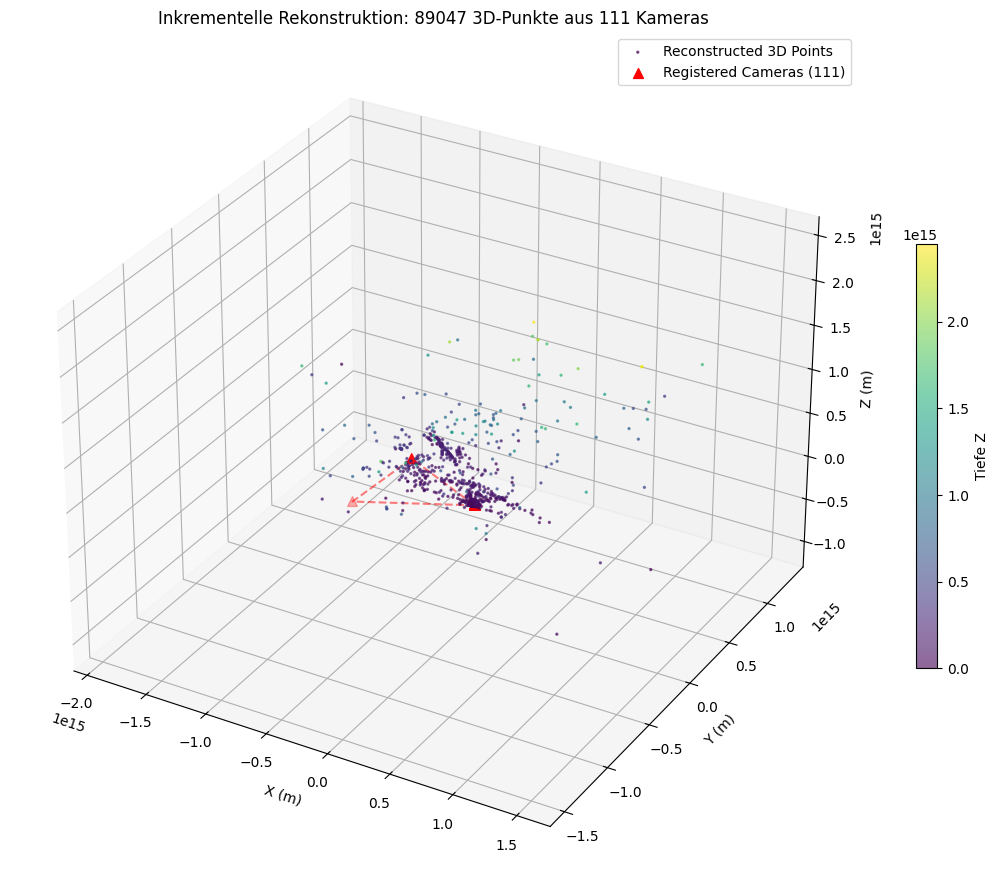

Successfully exported 89047 3D points to /home/semi/projects/propyläen_3d_reconstruct/outputs/final_reconstruction.ply
Gereinigtes 3D-Modell erfolgreich gespeichert unter: /home/semi/projects/propyläen_3d_reconstruct/outputs/final_reconstruction.ply


In [8]:
import matplotlib.pyplot as plt
import numpy as np
import open3d as o3d

# 1. Clean Point Cloud (Remove Wild Distance Outliers)
pcd = o3d.geometry.PointCloud()
pcd.points = o3d.utility.Vector3dVector(global_point_cloud)

# Filter out points whose distance is beyond 2 standard deviations
clean_pcd, _ = pcd.remove_statistical_outlier(nb_neighbors=50, std_ratio=2.0)
clean_points = np.asarray(clean_pcd.points)

print(
    f"Cleaned Point Cloud: Reduced from {len(global_point_cloud)} to"
    f" {len(clean_points)} points."
)

# 2. 3D Plot of Cleaned Point Cloud and Registered Cameras

fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection="3d")

# Visualisiere die GEREINIGTE 3D-Punktwolke (farblich nach Tiefe Z codiert)
scatter = ax.scatter(
    clean_points[:, 0],
    clean_points[:, 1],
    clean_points[:, 2],
    c=clean_points[:, 2],
    cmap="viridis",
    s=2,
    alpha=0.6,
    label="Reconstructed 3D Points",
)

# Plotting C = -R^T * T)
cam_centers = []
for idx, cam_data in registered_cameras.items():
  R_c = cam_data["R"]
  T_c = cam_data["T"]
  C = (-R_c.T @ T_c).ravel()
  cam_centers.append(C)

cam_centers = np.array(cam_centers)

# Kameras
ax.scatter(
    cam_centers[:, 0],
    cam_centers[:, 1],
    cam_centers[:, 2],
    c="red",
    s=50,
    marker="^",
    label=f"Registered Cameras ({len(cam_centers)})",
)

# Trajectory of camera pos
ax.plot(
    cam_centers[:, 0],
    cam_centers[:, 1],
    cam_centers[:, 2],
    c="red",
    linestyle="--",
    alpha=0.5,
)

# Axes
ax.set_xlabel("X (m)")
ax.set_ylabel("Y (m)")
ax.set_zlabel("Z (m)")
ax.set_title(
    f"Inkrementelle Rekonstruktion: {len(clean_points)} 3D-Punkte aus"
    f" {len(registered_cameras)} Kameras"
)
ax.legend()
fig.colorbar(scatter, ax=ax, shrink=0.5, label="Tiefe Z")

plt.tight_layout()
plt.show()

# 3. Export Cleaned Pointcloud as PLY File
output_file = PROJECT_ROOT / "outputs" / "final_reconstruction.ply"
output_file.parent.mkdir(parents=True, exist_ok=True)

export_ply(str(output_file), clean_points)
print(f"Gereinigtes 3D-Modell erfolgreich gespeichert unter: {output_file}")